# **Ouroboros RL x LLM**

### **Reinforcement Learning and Large Language Models for the Discovery of Computational Models of the Human Brain**

#### Maël Donoso, [Ouroboros Neurotechnologies](https://ouroboros-neurotechnologies.com)

## **Proof-of-concept experiment**

#### **Implementation details**

**Data:** The EEG-fMRI neurofeedback dataset used for the proof-of-concept experiment can be found here: https://openneuro.org/datasets/ds002336/versions/2.0.2. It is described in the paper: Giulia Lioi, Claire Cury, Lorraine Perronnet, Marsel Mano, Elise Bannier, Anatole Lécuyer, and Christian Barillot. *Simultaneous EEG-fMRI during a neurofeedback task, a brain imaging dataset for multimodal data integration*. Scientific Data, 7(1):173, 2020. https://doi.org/10.1038/s41597-020-0498-3. This dataset includes ten subjects and three main experimental conditions: eegNF, fmriNF, eegfmriNF. Within this dataset, we use the fMRI data and focus on the eegNF condition, where the neurofeedback scores are provided to the subjects based on their EEG activity. Since subject 2 has a missing eegNF condition, we exclude this subject from the experiment. For the exploratory data analysis, we use subject 1 for training and subject 3 for validation. For the experiment itself, we use the remaining subjects: subjects 4, 6, 8, and 10 are used as the training+validation set, and subjects 5, 7, and 9 as the test set. 

**Models:** Computational models are restricted to non-trivial polynomials, and can only use three variables, denoted x1, x2, and x3. These variables correspond to the mean EEG neurofeedback scores computed during three successive 5-second windows preceding an fMRI scan, with x1 corresponding to the most recent window. We expect these variables to capture some mean reward or error effects experienced by the subjects as they are presented with the neurofeedback scores. However, for the purpose of this proof-of-concept experiment, we formulate no particular neuroscience hypothesis or interpretation about these effects. 

**Search:** At the beginning of the experiment, an initial computational model is created. Then, the experiment is run for ten iterations, with three model variants per iteration evaluated on the training+validation set. The incumbent model is also evaluated on the test set, but its score is not used to guide the search process. Within each group of subjects (the training+validation set or the test set), evaluation is conducted by retrieving the subject-level brain statistical maps (first-level beta maps) within the group brain mask, and averaging the Pearson correlation coefficients across unique pairs of subjects. The error bars correspond to the standard error across these pairwise correlations, and are only given as descriptive statistics, since the objective is to illustrate some fundamental building blocks of the inner loop and not to discover a scientifically relevant model. 

**Safeguards:** Simple safeguards are implemented to verify that the generated polynomials respect our criteria. The validity of each generated polynomial is verified by a dedicated function, and an error is raised if no valid polynomial is found after 25 attempts (no such error was raised during the experiment). Then, valid polynomials are compared with the history, and rejected if they are identical to a previous polynomial. If no original variant is found after testing five valid polynomials, the LLM is prompted to apply two modifications to the parent polynomial instead of one. If this strategy does not result in an original variant either, the LLM is prompted to remove the first term of the polynomial and add an entirely new term. 

#### **Preprocessing**

Before running the Notebook, the fMRI data needs to be preprocessed with fMRIPrep 23.2.0: https://fmriprep.org/en/23.2.0/index.html. Specifically, it needs to be normalized using the MNI152Lin output space, while ignoring slice timing correction. If the user chooses, as is recommended, the Docker execution with the fmriprep-docker wrapper described in https://fmriprep.org/en/23.2.0/installation.html, running fMRIPrep with these parameters can be done by executing a command such as this one for subjects sub-xp101 to sub-xp110:

*fmriprep-docker ds002336-download neuroimaging_data participant --participant-label sub-xp101 --fs-license-file freesurfer/license.txt --ignore slicetiming --output-spaces MNI152Lin*

Before running the fMRIPrep command, the .bidsignore file given in the project directory (.bidsignore) should be added to the dataset directory, and a FreeSurfer license (freesurfer/license.txt) should be requested here: https://surfer.nmr.mgh.harvard.edu/registration.html. 

The conda environment for this Notebook can be recreated with the .yml file given in the project directory (env.yml). 

In [1]:
# Define the local paths to the experimental and neuroimaging datasets. 
# This should be a Python file named '_local_paths.py', containing two variables: experimental_dataset_path and neuroimaging_dataset_path. 
from _local_paths import experimental_dataset_path, neuroimaging_dataset_path

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import nibabel as nib
from nilearn.glm.first_level.hemodynamic_models import spm_hrf
import h5py
import random
import torch
from transformers import AutoProcessor, AutoModelForCausalLM
import ast
import math
import pickle
import json

In [3]:
# Define the list of subjects. 
subjects = ['sub-xp1' + str(x).zfill(2) for x in range(1, 11)]

# Define the training and validation subjects, the condition, and the fMRI repetition time (TR) in seconds. 
train_subject = 'sub-xp101'
valid_subject = 'sub-xp103'
condition = 'eegNF'
fmri_tr = 2

### Brain images

Retrieve the brain images, which must be preprocessed using fMRIPrep. Based on the *Data Records* section of the (Lioi et al., 2020) paper, the first scan should be discarded. 

In [4]:
# Load the training and validation brain images in NIFTI format. 
train_image_nifti = nib.load(neuroimaging_dataset_path + train_subject + '/func/' +  train_subject + '_task-' + condition + '_space-MNI152Lin_desc-preproc_bold.nii.gz')
valid_image_nifti = nib.load(neuroimaging_dataset_path + valid_subject + '/func/' +  valid_subject + '_task-' + condition + '_space-MNI152Lin_desc-preproc_bold.nii.gz')

# Extract the brain images data, and display their size and number of scans. 
train_image = train_image_nifti.get_fdata()
valid_image = valid_image_nifti.get_fdata()
print('Brain image dimensions (Training):  ', train_image.shape)
print('Brain image dimensions (Validation):', valid_image.shape)

# Retrieve the minimum number of scans between the training and validation conditions. 
nb_scans = min(train_image.shape[3], valid_image.shape[3])
print('Minimum number of scans:            ', nb_scans)

Brain image dimensions (Training):   (76, 95, 40, 205)
Brain image dimensions (Validation): (76, 95, 40, 210)
Minimum number of scans:             205


In [5]:
# Shorten the training and validation brain images to the minimum number of scans. 
train_image = train_image[:, :, :, :nb_scans]
valid_image = valid_image[:, :, :, :nb_scans]

# Remove the first scan from the training and validation brain images, and adapt the number of scans. 
train_image = train_image[:, :, :, 1:]
valid_image = valid_image[:, :, :, 1:]
nb_scans = nb_scans - 1

# Display the new size of the training and validation brain images. 
print('Brain image dimensions (Training):  ', train_image.shape)
print('Brain image dimensions (Validation):', valid_image.shape)
print('Minimum number of scans:            ', nb_scans)

Brain image dimensions (Training):   (76, 95, 40, 204)
Brain image dimensions (Validation): (76, 95, 40, 204)
Minimum number of scans:             204


In [6]:
# Define a function to return the middle sections of a brain image. 
def middle_sections(image_data):
    middle = np.array(image_data[:, :, :].shape) / 2
    return tuple(int(value) for value in middle)

In [7]:
# Define a function to display sections of a brain image through the sagittal, coronal, and axial views. 
def display_brain_image(image_data, middle_coord, save_image = False, image_filename = None, colormap = 'viridis', scan = 0):
    fig, axes = plt.subplots(nrows = 1, ncols = 3, figsize = (12, 5))

    # If the image_data array contains several scans, select the scan given as argument. 
    if len(image_data.shape) == 4:
        image_data = image_data[:, :, :, scan]

    axes[0].imshow(image_data[middle_coord[0], :, :].T, cmap = colormap, origin = 'lower')
    axes[0].set_title('Sagittal view')
    axes[1].imshow(image_data[:, middle_coord[1], :].T, cmap = colormap, origin = 'lower')
    axes[1].set_title('Coronal view')
    axes[2].imshow(image_data[:, :, middle_coord[2]], cmap = colormap, origin = 'lower')
    axes[2].set_title('Axial view')

    # If save_image is True, save the figure to the specified image_filename. 
    if save_image:
        plt.savefig(image_filename, dpi = 300, bbox_inches = 'tight')
        
    plt.show()

Middle coordinates: (38, 47, 20)


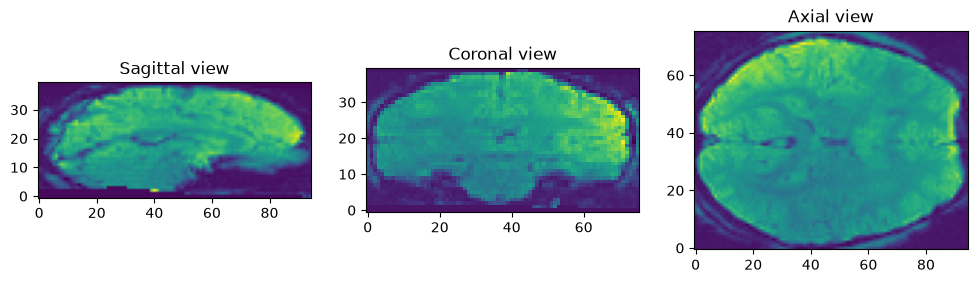

In [8]:
# Find the middle section coordinates of the training brain image.
middle_coord = middle_sections(train_image[:, :, :, 0])
print('Middle coordinates:', middle_coord)

# Display sections of the training brain image through the sagittal, coronal, and axial views. 
display_brain_image(train_image, middle_coord, save_image = True, image_filename = 'brain_data_image.png')

In [9]:
# Load the training and validation brain masks in NIFTI format. 
train_mask_nifti = nib.load(neuroimaging_dataset_path + train_subject + '/func/' +  train_subject + '_task-' + condition + '_space-MNI152Lin_desc-brain_mask.nii.gz')
valid_mask_nifti = nib.load(neuroimaging_dataset_path + valid_subject + '/func/' +  valid_subject + '_task-' + condition + '_space-MNI152Lin_desc-brain_mask.nii.gz')

# Extract the brain masks data. 
train_mask = train_mask_nifti.get_fdata()
valid_mask = valid_mask_nifti.get_fdata()

# Combine the training and validation brain masks to create a single mask, and display its size.
brain_mask = np.logical_and(train_mask, valid_mask).astype(bool)
print('Brain mask size:', brain_mask.shape)

Brain mask size: (76, 95, 40)


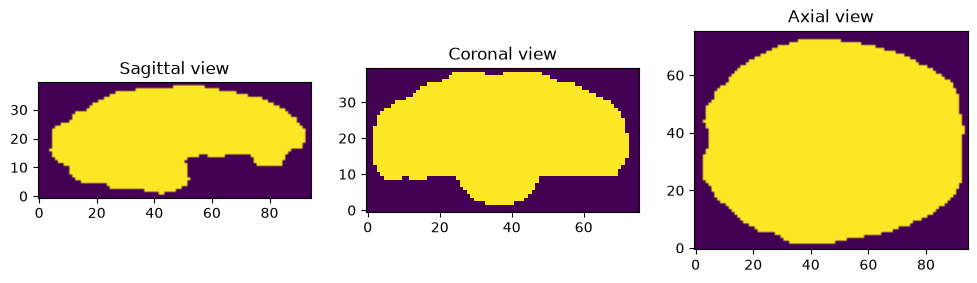

In [10]:
# Display sections of the brain mask through the sagittal, coronal, and axial views. 
display_brain_image(brain_mask, middle_coord, save_image = True, image_filename = 'brain_mask_image.png')

In [11]:
# Convert the brain mask values to Boolean. 
binary_mask_3d = brain_mask.astype(bool)

# Convert the 3D binary mask into a 4D binary mask, by repeating Boolean values along a 4th dimension. 
binary_mask_4d = np.repeat(binary_mask_3d[:, :, :, np.newaxis], nb_scans, axis = 3)
print('Brain mask size:', binary_mask_4d.shape)

Brain mask size: (76, 95, 40, 204)


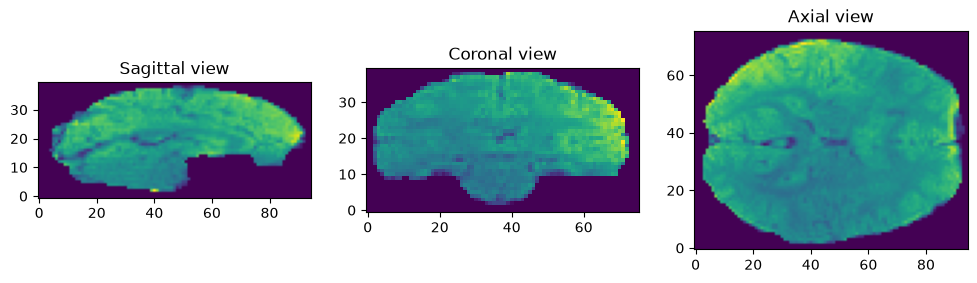

In [12]:
# Transform the training and validation brain images according to the binary mask. 
train_image = train_image * binary_mask_4d
valid_image = valid_image * binary_mask_4d

# Display sections of the training brain image through the sagittal, coronal, and axial views. 
display_brain_image(train_image, middle_coord)

### Neurofeedback scores

Retrieve the EEG neurofeedback scores. Based on the *Methods* section of the (Lioi et al., 2020) paper, these neurofeedback scores were updated every 0.25 second. 

In [13]:
# Define the neurofeedback scores paths. 
train_nf_scores_path = experimental_dataset_path + 'derivatives/' + train_subject + '/NF_eeg/d_' + train_subject + '_task-' + condition + '_NFeeg_scores.mat'
valid_nf_scores_path = experimental_dataset_path + 'derivatives/' + valid_subject + '/NF_eeg/d_' + valid_subject + '_task-' + condition + '_NFeeg_scores.mat'

# Retrieve the EEG neurofeedback scores for the training condition. 
with h5py.File(train_nf_scores_path, 'r') as mat_data:
    train_nf_scores = mat_data['NF_eeg/nf_laterality'][:].squeeze()

# Retrieve the EEG neurofeedback scores for the validation condition. 
with h5py.File(valid_nf_scores_path, 'r') as mat_data:
    valid_nf_scores = mat_data['NF_eeg/nf_laterality'][:].squeeze()

In [14]:
# Display the number of neurofeedback scores for the training and validation conditions. 
print('Number of neurofeedback scores (Training):  ', len(train_nf_scores))
print('Number of neurofeedback scores (Validation):', len(valid_nf_scores))

Number of neurofeedback scores (Training):   1600
Number of neurofeedback scores (Validation): 1600


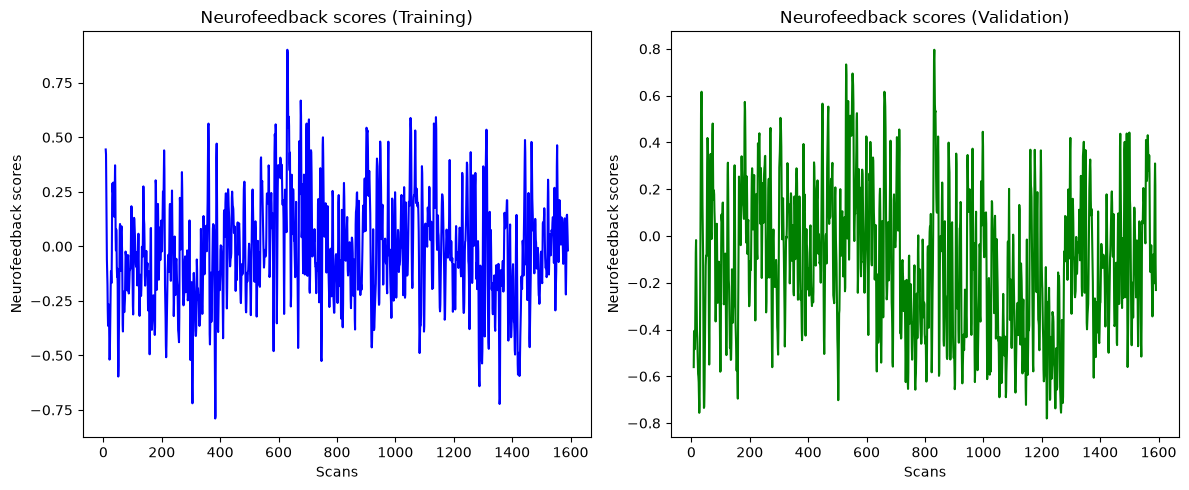

In [15]:
# Plot the neurofeedback scores for the training and validation conditions. 
plt.figure(figsize = (12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_nf_scores, color = 'blue', label = 'Training condition')
plt.title('Neurofeedback scores (Training)')
plt.xlabel('Scans')
plt.ylabel('Neurofeedback scores')

plt.subplot(1, 2, 2)
plt.plot(valid_nf_scores, color = 'green', label = 'Validation condition')
plt.title('Neurofeedback scores (Validation)')
plt.xlabel('Scans')
plt.ylabel('Neurofeedback scores')
plt.tight_layout()

# Save the plot of the neurofeedback scores for the training and validation conditions. 
plt.savefig('neurofeedback_scores_plot.png', dpi = 300, bbox_inches = 'tight')

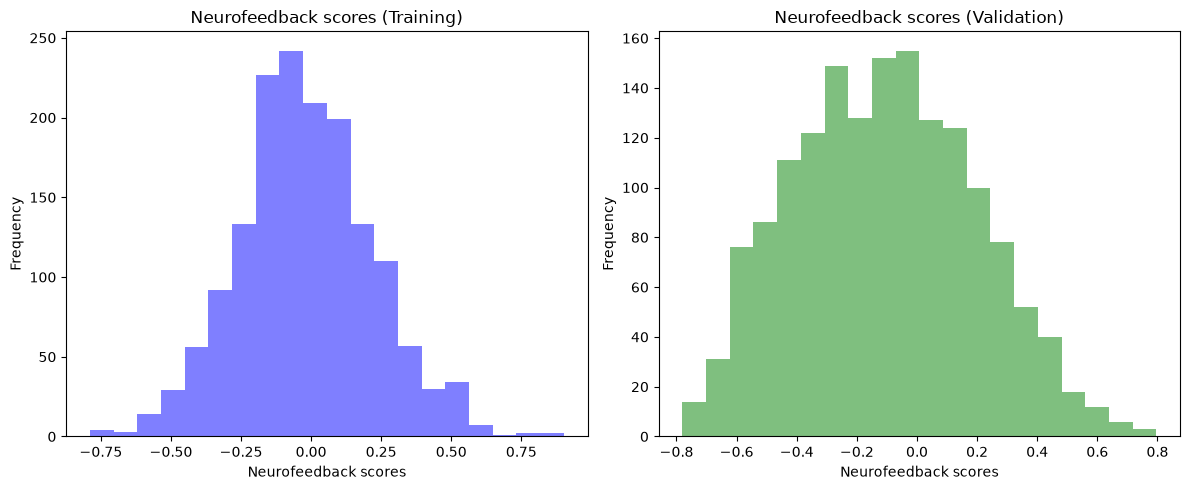

In [16]:
# Display the histogram of the neurofeedback scores for the training and validation conditions. 
plt.figure(figsize = (12, 5))
plt.subplot(1, 2, 1)
plt.hist(train_nf_scores, bins = 20, color = 'blue', alpha = 0.5, label = 'Training condition')
plt.title('Neurofeedback scores (Training)')
plt.xlabel('Neurofeedback scores')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(valid_nf_scores, bins = 20, color = 'green', alpha = 0.5, label = 'Validation condition')
plt.title('Neurofeedback scores (Validation)')
plt.xlabel('Neurofeedback scores')
plt.ylabel('Frequency')
plt.tight_layout()

# Save the histogram of the neurofeedback scores for the training and validation conditions. 
plt.savefig('neurofeedback_scores_histogram.png', dpi = 300, bbox_inches = 'tight')

In [17]:
# Display the mean and standard deviation of the neurofeedback scores for the training and validation conditions. 
print('Mean (Training):  ', np.nanmean(train_nf_scores))
print('Mean (Validation):', np.nanmean(valid_nf_scores))
print('Standard deviation (Training):  ', np.nanstd(train_nf_scores))
print('Standard deviation (Validation):', np.nanstd(valid_nf_scores))

Mean (Training):   -0.017516901455027004
Mean (Validation): -0.1075832891898583
Standard deviation (Training):   0.23689032166697135
Standard deviation (Validation): 0.30061333678632324


In [18]:
# Display the first 10 neurofeedback scores for the training and validation conditions. 
print('First 10 neurofeedback scores (Training):')
print(train_nf_scores[0:10])
print('First 10 neurofeedback scores (Validation):')
print(valid_nf_scores[0:10])

First 10 neurofeedback scores (Training):
[       nan        nan        nan        nan        nan        nan
        nan        nan 0.4442749  0.42148292]
First 10 neurofeedback scores (Validation):
[        nan         nan         nan         nan         nan         nan
         nan         nan -0.56066559 -0.41542188]


In [19]:
# Display the last 10 neurofeedback scores for the training and validation conditions. 
print('Last 10 neurofeedback scores (Training):')
print(train_nf_scores[-10:])
print('Last 10 neurofeedback scores (Validation):')
print(valid_nf_scores[-10:])

Last 10 neurofeedback scores (Training):
[ 0.04286465 -0.01815645         nan         nan         nan         nan
         nan         nan         nan         nan]
Last 10 neurofeedback scores (Validation):
[-0.12080109 -0.23109334         nan         nan         nan         nan
         nan         nan         nan         nan]


In [20]:
# Remove the first 8 and last 8 neurofeedback scores for the training and validation conditions. 
scores_per_scan = 8
train_nf_scores = train_nf_scores[scores_per_scan:-scores_per_scan]
valid_nf_scores = valid_nf_scores[scores_per_scan:-scores_per_scan]

# Remove the first and last scans from the training and validation brain images, and adapt the number of scans. 
train_image = train_image[:, :, :, 1:-1]
valid_image = valid_image[:, :, :, 1:-1]
nb_scans = nb_scans - 2

# Display the new number of neurofeedback scores for the training and validation conditions. 
print('Number of neurofeedback scores (Training):  ', len(train_nf_scores))
print('Number of neurofeedback scores (Validation):', len(valid_nf_scores))

Number of neurofeedback scores (Training):   1584
Number of neurofeedback scores (Validation): 1584


In [21]:
# Find the minimum number of neurofeedback scores for which there is both enough brain images and enough neurofeedback scores for the training and validation conditions. 
nb_nf_scores = min(nb_scans * scores_per_scan, len(train_nf_scores), len(valid_nf_scores))
nb_nf_scores

# Truncate the neurofeedback scores for the training and validation conditions to the minimum number of neurofeedback scores. 
train_nf_scores = train_nf_scores[:nb_nf_scores]
valid_nf_scores = valid_nf_scores[:nb_nf_scores]

# Truncate the training and validation brain images to the minimum number of neurofeedback scores. 
nb_scans = nb_nf_scores // scores_per_scan
train_image = train_image[:, :, :, :nb_scans]
valid_image = valid_image[:, :, :, :nb_scans]

# Display the new number of brain images and neurofeedback scores for the training and validation conditions. 
print('Number of brain images (Training):  ', train_image.shape[3])
print('Number of brain images (Validation):', valid_image.shape[3])
print('Number of neurofeedback scores (Training):  ', len(train_nf_scores))
print('Number of neurofeedback scores (Validation):', len(valid_nf_scores))

# Display the remaining number of NaN neurofeedback scores for the training and validation conditions. 
print('Number of NaN neurofeedback scores (Training):  ', np.sum(np.isnan(train_nf_scores)))
print('Number of NaN neurofeedback scores (Validation):', np.sum(np.isnan(valid_nf_scores)))

Number of brain images (Training):   198
Number of brain images (Validation): 198
Number of neurofeedback scores (Training):   1584
Number of neurofeedback scores (Validation): 1584
Number of NaN neurofeedback scores (Training):   0
Number of NaN neurofeedback scores (Validation): 0


### Regressors

Define an example computational model. Compute the regressors to be used in the fMRI analysis, including the model-derived regressor and the movement regressors. 

In [22]:
# Define the computational model. 
computational_model = 'x1 + 3.10*x2 + 5.25*x3 + x2**2 + 2.58*x1*x2'

In [23]:
# Define a function to create an HRF-convolved fMRI regressor from a polynomial model. 
def create_model_regressor(
    computational_model, 
    nf_scores, 
    nb_scans, 
    scores_per_scan = 8, 
    scores_per_window = 20
    ):

    # Retrieve the neurofeedback scores. 
    nf_scores = np.asarray(nf_scores).squeeze()

    # Define the output computed by the computational model. 
    computational_model_output = np.zeros(nb_scans)

    # Iterate over the scans to compute the model output based on the neurofeedback scores. 
    for scan_index in range(nb_scans):
        score_index = scan_index * scores_per_scan

        # If no complete 15-second history is available, keep the model output at zero. 
        if score_index < 3 * scores_per_window:
            continue

        # Otherwise, compute the model output based on the neurofeedback scores. 
        x1 = np.mean(
            nf_scores[score_index - scores_per_window : score_index]
        )
        x2 = np.mean(
            nf_scores[
                score_index - 2 * scores_per_window :
                score_index - scores_per_window
            ]
        )
        x3 = np.mean(
            nf_scores[
                score_index - 3 * scores_per_window :
                score_index - 2 * scores_per_window
            ]
        )

        computational_model_output[scan_index] = eval(
            computational_model,
            {},
            {'x1': x1, 'x2': x2, 'x3': x3},
        )

    # Convolve the scan-level computational model output with a canonical HRF.
    hrf = spm_hrf(t_r = fmri_tr, oversampling = 1)
    convolved_regressor = np.convolve(computational_model_output, hrf, mode = 'full')[:nb_scans]

    return computational_model_output, convolved_regressor

In [24]:
# Create the regressors for the training and validation conditions based on the computational model and the neurofeedback scores. 
train_variable, train_regressor = create_model_regressor(computational_model, train_nf_scores, nb_scans)
valid_variable, valid_regressor = create_model_regressor(computational_model, valid_nf_scores, nb_scans)

# Display the size of the regressors for the training and validation conditions. 
print('Regressor size (Training):  ', train_regressor.shape)
print('Regressor size (Validation):', valid_regressor.shape)

Regressor size (Training):   (198,)
Regressor size (Validation): (198,)


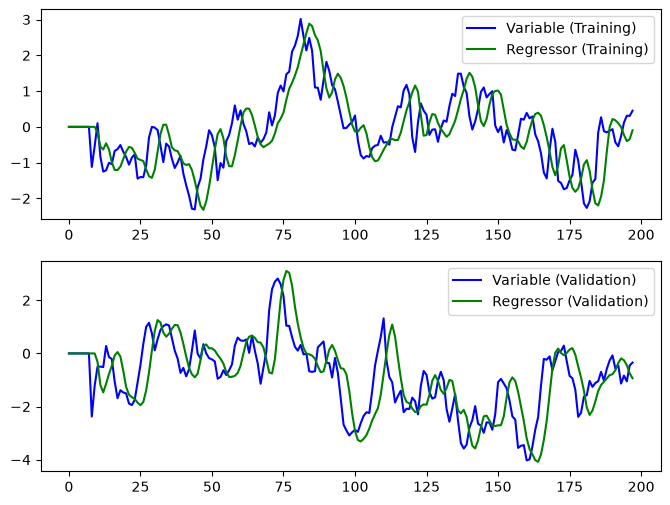

In [25]:
# Plot the variables and regressors for the training and validation conditions. 
plt.figure(figsize = (8, 6))
plt.subplot(2, 1, 1)
plt.plot(train_variable, label = 'Variable (Training)', color = 'blue')
plt.plot(train_regressor, label = 'Regressor (Training)', color = 'green')
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(valid_variable, label = 'Variable (Validation)', color = 'blue')
plt.plot(valid_regressor, label = 'Regressor (Validation)', color = 'green')
plt.legend()

# Save the plot of the variables and regressors for the training and validation conditions. 
plt.savefig('variables_and_regressors_plot.png', dpi = 300, bbox_inches = 'tight')

In [26]:
# Define the movement regressors time-series paths.
train_movement_regressors_path = (neuroimaging_dataset_path + train_subject + '/func/' + train_subject + '_task-' + condition + '_desc-confounds_timeseries.tsv')
valid_movement_regressors_path = (neuroimaging_dataset_path + valid_subject + '/func/' + valid_subject + '_task-' + condition + '_desc-confounds_timeseries.tsv')

# Load the movement regressors tables.
train_movement_regressors = pd.read_csv(train_movement_regressors_path, sep = '\t')
valid_movement_regressors = pd.read_csv(valid_movement_regressors_path, sep = '\t')

# Define the movement regressors columns. 
movement_regressors_columns = ['trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z']

# Retrieve the movement regressors for the training and validation conditions, excluding the discarded scans. 
train_movement_regressors = (train_movement_regressors[movement_regressors_columns].iloc[2:nb_scans + 2].to_numpy(dtype = float))
valid_movement_regressors = (valid_movement_regressors[movement_regressors_columns].iloc[2:nb_scans + 2].to_numpy(dtype = float))

# Display the shape of the movement regressors for the training and validation conditions. 
print('Movement regressors (Training):  ', train_movement_regressors.shape)
print('Movement regressors (Validation):', valid_movement_regressors.shape)

Movement regressors (Training):   (198, 6)
Movement regressors (Validation): (198, 6)


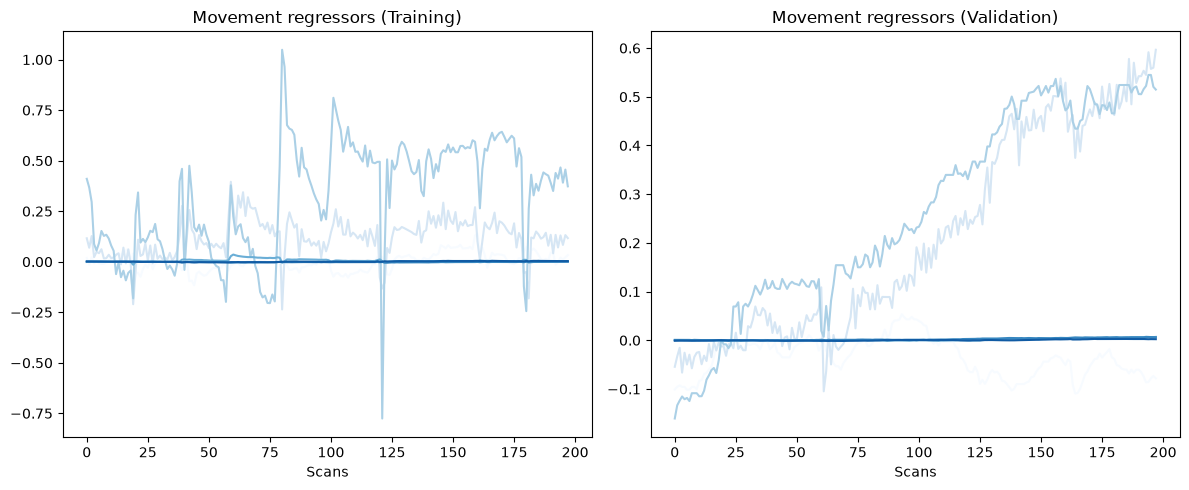

In [27]:
# Plot the movement regressors for the training and validation conditions. 
plt.figure(figsize = (12, 5))
plt.subplot(1, 2, 1)
for i in range(train_movement_regressors.shape[1]):
    plt.plot(train_movement_regressors[:, i], color = plt.cm.Blues(i / train_movement_regressors.shape[1]))
plt.title('Movement regressors (Training)')
plt.xlabel('Scans')

plt.subplot(1, 2, 2)
for i in range(valid_movement_regressors.shape[1]):
    plt.plot(valid_movement_regressors[:, i], color = plt.cm.Blues(i / valid_movement_regressors.shape[1]))
plt.title('Movement regressors (Validation)')
plt.xlabel('Scans')
plt.tight_layout()

# Save the plot of the movement regressors for the training and validation conditions. 
plt.savefig('movement_regressors_plot.png', dpi = 300, bbox_inches = 'tight')

### Brain statistical maps

Run the fMRI analysis to obtain the brain statistical maps. 

In [28]:
# Define a function to run a first-level analysis of fMRI data using the model-derived regressor and the movement regressors. 
def run_first_level_analysis(
    image_data, 
    nb_scans, 
    brain_mask, 
    model_regressor, 
    movement_regressors
):

    # Normalize the regressors for numerical stability. 
    model_regressor = (model_regressor - np.mean(model_regressor)) / np.std(model_regressor)
    movement_regressors = (movement_regressors - np.mean(movement_regressors, axis = 0)) / np.std(movement_regressors, axis = 0)

    # Include an intercept and a linear drift term. 
    linear_drift = np.linspace(-1, 1, nb_scans)
    design_matrix = np.column_stack(
        [
            np.ones(nb_scans), 
            linear_drift, 
            model_regressor, 
            movement_regressors
        ]
    )

    # Reshape the masked fMRI data as scans × voxels.
    brain_time_series = image_data[brain_mask].T

    # Estimate all voxelwise regression coefficients simultaneously. 
    beta_coefficients = np.linalg.lstsq(
        design_matrix, 
        brain_time_series, 
        rcond = None
    )[0]

    # Retrieve the coefficients for the model regressor, which corresponds to the third column of the design matrix. 
    model_beta_values = beta_coefficients[2]

    # Restore the beta values to a three-dimensional brain map. 
    model_beta_map = np.zeros(brain_mask.shape)
    model_beta_map[brain_mask] = model_beta_values

    return model_beta_map, design_matrix

In [29]:
# Run the first-level analysis for the training condition. 
train_beta_map, train_design_matrix = run_first_level_analysis(
    train_image, 
    nb_scans, 
    brain_mask, 
    train_regressor, 
    train_movement_regressors
)

# Run the first-level analysis for the validation condition. 
valid_beta_map, valid_design_matrix = run_first_level_analysis(
    valid_image, 
    nb_scans, 
    brain_mask, 
    valid_regressor, 
    valid_movement_regressors
)

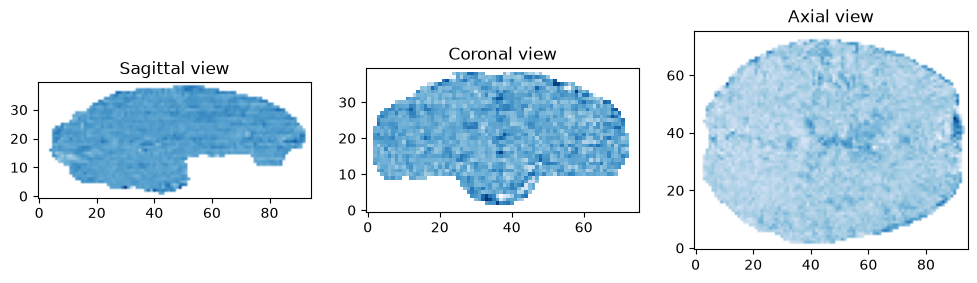

In [30]:
# Replace values outside the brain mask with NaN in the training and validation beta maps. 
train_beta_map[~brain_mask] = np.nan
valid_beta_map[~brain_mask] = np.nan

# Display sections of the training brain statistical map through the sagittal, coronal, and axial views. 
display_brain_image(train_beta_map, middle_coord, save_image = True, image_filename = 'train_beta_map_image.png', colormap = 'Blues')

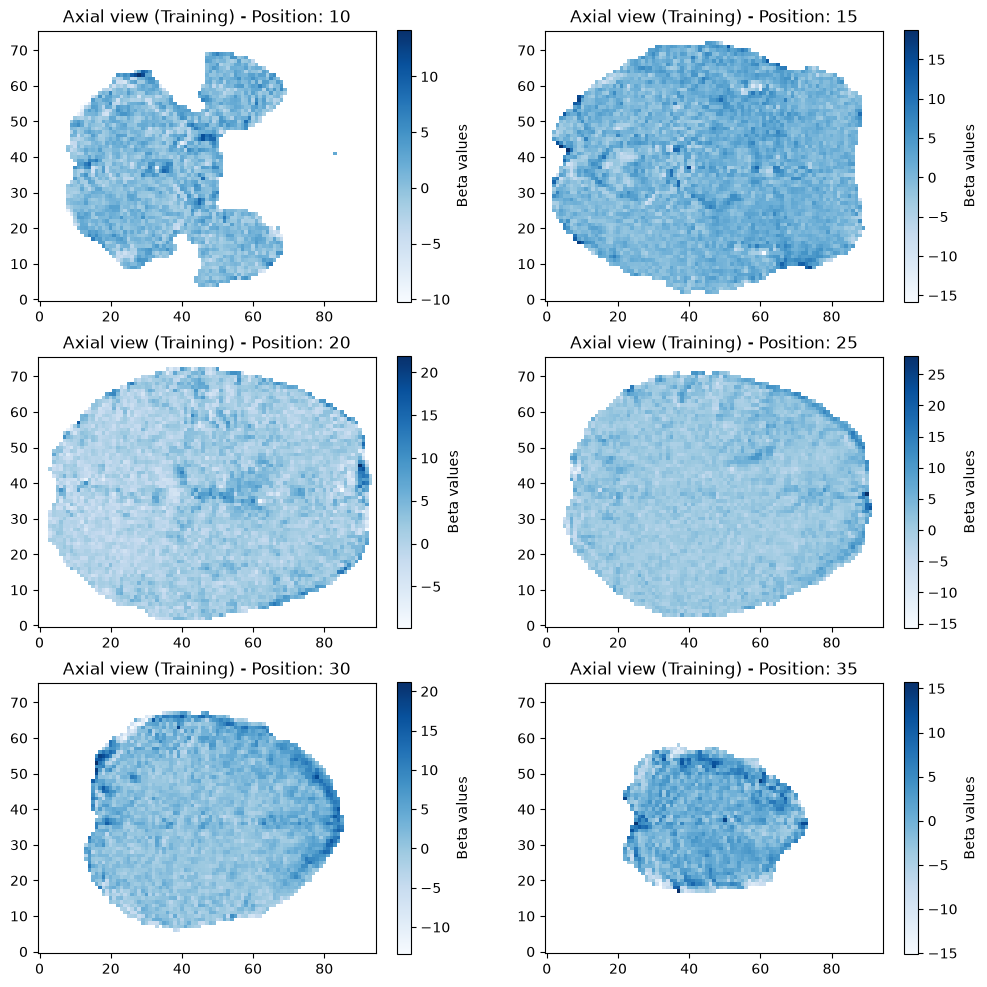

In [31]:
# Display a succession of axial views at different positions of the training brain statistical map. 
plt.figure(figsize = (12, 12))
for axial_position in range(10, 40, 5):
    plt.subplot(3, 2, (axial_position - 10) // 5 + 1)
    plt.imshow(train_beta_map[:, :, axial_position], origin = 'lower', cmap = 'Blues')
    plt.title('Axial view (Training) - Position: ' + str(axial_position))
    plt.colorbar(label = 'Beta values')

# Save the succession of axial views at different positions of the brain statistical map. 
plt.savefig('brain_statistical_map_axial_views.png', dpi = 300, bbox_inches = 'tight')

plt.show()

In [32]:
# Compute and display a Pearson correlation coefficient between the training and validation brain statistical maps. 
similarity_score = np.corrcoef(
    train_beta_map.flatten()[brain_mask.flatten()],
    valid_beta_map.flatten()[brain_mask.flatten()]
)[0, 1]
print('Similarity score (Pearson correlation):', similarity_score)

Similarity score (Pearson correlation): -0.02928552778972581


### Group analysis

Replicate the fMRI analysis for a group of subjects. 

In [33]:
# Define dictionaries to store the brain images, brain masks, neurofeedback scores, and movement regressors for all subjects. 
brain_images_dict = {}
brain_masks_dict = {}
neurofeedback_scores_dict = {}
movement_regressors_dict = {}

# Retrieve the brain images, brain masks, neurofeedback scores, and movement regressors for all subjects, and store them in the dictionaries. 
for subject in subjects:

    # Skip subject sub-xp102, which has a missing eegNF condition. 
    if subject == 'sub-xp102':
        continue

    # Load the brain image in NIFTI format, extract the brain image data, and store it in the dictionary. 
    image_nifti = nib.load(neuroimaging_dataset_path + subject + '/func/' +  subject + '_task-' + condition + '_space-MNI152Lin_desc-preproc_bold.nii.gz')
    image_data = image_nifti.get_fdata()
    brain_images_dict[subject] = image_data

    # Load the brain mask in NIFTI format, extract the brain mask data, and store it in the dictionary. 
    mask_nifti = nib.load(neuroimaging_dataset_path + subject + '/func/' +  subject + '_task-' + condition + '_space-MNI152Lin_desc-brain_mask.nii.gz')
    mask_data = mask_nifti.get_fdata()
    brain_masks_dict[subject] = mask_data

    # Retrieve the neurofeedback scores, and store them in the dictionary. 
    nf_scores_path = experimental_dataset_path + 'derivatives/' + subject + '/NF_eeg/d_' + subject + '_task-' + condition + '_NFeeg_scores.mat'
    with h5py.File(nf_scores_path, 'r') as mat_data:
        nf_scores = mat_data['NF_eeg/nf_laterality'][:].squeeze()
    neurofeedback_scores_dict[subject] = nf_scores

    # Load the movement regressors table, retrieve the movement regressors, and store them in the dictionary. 
    movement_regressors_path = neuroimaging_dataset_path + subject + '/func/' + subject + '_task-' + condition + '_desc-confounds_timeseries.tsv'
    movement_regressors_table = pd.read_csv(movement_regressors_path, sep = '\t')
    movement_regressors = movement_regressors_table[movement_regressors_columns].iloc[2:nb_scans + 2].to_numpy(dtype = float)
    movement_regressors_dict[subject] = movement_regressors

In [34]:
# Verify that the dictionaries contain the expected keys for all included subjects. 
brain_images_dict.keys(), brain_masks_dict.keys(), neurofeedback_scores_dict.keys(), movement_regressors_dict.keys()

(dict_keys(['sub-xp101', 'sub-xp103', 'sub-xp104', 'sub-xp105', 'sub-xp106', 'sub-xp107', 'sub-xp108', 'sub-xp109', 'sub-xp110']),
 dict_keys(['sub-xp101', 'sub-xp103', 'sub-xp104', 'sub-xp105', 'sub-xp106', 'sub-xp107', 'sub-xp108', 'sub-xp109', 'sub-xp110']),
 dict_keys(['sub-xp101', 'sub-xp103', 'sub-xp104', 'sub-xp105', 'sub-xp106', 'sub-xp107', 'sub-xp108', 'sub-xp109', 'sub-xp110']),
 dict_keys(['sub-xp101', 'sub-xp103', 'sub-xp104', 'sub-xp105', 'sub-xp106', 'sub-xp107', 'sub-xp108', 'sub-xp109', 'sub-xp110']))

In [35]:
# Define subjects 4, 6, 8, 10 as the training and validation subjects, and subjects 5, 7, 9 as the test subjects.
train_valid_subjects = ['sub-xp1' + str(x).zfill(2) for x in [4, 6, 8, 10]]
test_subjects = ['sub-xp1' + str(x).zfill(2) for x in [5, 7, 9]]

# Display the training and validation subjects, and the test subjects. 
print('Training and validation subjects:', train_valid_subjects)
print('Test subjects:                   ', test_subjects)

Training and validation subjects: ['sub-xp104', 'sub-xp106', 'sub-xp108', 'sub-xp110']
Test subjects:                    ['sub-xp105', 'sub-xp107', 'sub-xp109']


In [36]:
# Define a function to prepare the brain images and brain masks for a group of subjects. 
def prepare_group_brain_images(
    group_subjects, 
    brain_images_dict, 
    brain_masks_dict, 
    group_nb_scans
):
    
    # Retrieve the brain images for all group subjects and remove the two first scans. 
    group_brain_images = {}
    for subject in group_subjects:
        group_brain_images[subject] = brain_images_dict[subject][:, :, :, 2:group_nb_scans + 2]
        
    # Retrieve and combine the brain masks for all group subjects. 
    group_brain_mask = np.ones(brain_masks_dict[group_subjects[0]].shape, dtype = bool)
    for subject in group_subjects:
        group_brain_mask = np.logical_and(group_brain_mask, brain_masks_dict[subject].astype(bool))

    # Convert the brain mask values to Boolean, and convert the 3D binary mask into a 4D binary mask.
    binary_mask_3d = group_brain_mask.astype(bool)
    binary_mask_4d = np.repeat(binary_mask_3d[:, :, :, np.newaxis], group_nb_scans, axis = 3)

    # Apply the group brain mask to all brain images. 
    for subject in group_subjects:
        group_brain_images[subject] = group_brain_images[subject] * binary_mask_4d

    return group_brain_images, group_brain_mask

In [37]:
# Define a function to run the first-level analysis on a group of subjects. 
def run_first_level_analysis_group(
    computational_model, 
    group_subjects, 
    group_nb_scans, 
    brain_images_dict, 
    brain_masks_dict, 
    neurofeedback_scores_dict, 
    movement_regressors_dict, 
    stored_brain_images_and_masks = dict(), 
    scores_per_scan = 8, 
    scores_per_window = 20
):

    # If stored brain images and brain masks are available, use them. 
    if stored_brain_images_and_masks:
        group_brain_images = stored_brain_images_and_masks['group_brain_images']
        group_brain_mask = stored_brain_images_and_masks['group_brain_mask']

    # Otherwise, prepare the brain images and brain masks for the group of subjects. 
    else:
        group_brain_images, group_brain_mask = prepare_group_brain_images(group_subjects, 
                                                                          brain_images_dict, 
                                                                          brain_masks_dict, 
                                                                          group_nb_scans)

    # Iterate through all group subjects to run the first-level analysis and store the brain statistical maps. 
    group_model_regressors = {}
    group_beta_maps = {}
    binary_mask_3d = group_brain_mask.astype(bool)
    
    for subject in group_subjects:

        # Retrieve and truncate the neurofeedback scores. 
        neurofeedback_scores = neurofeedback_scores_dict[subject]
        neurofeedback_scores = neurofeedback_scores[scores_per_scan:-scores_per_scan]

        # Retrieve and truncate the movement regressors. 
        movement_regressors = movement_regressors_dict[subject][:group_nb_scans]

        # Create the model regressor based on the computational model and the neurofeedback scores. 
        _, model_regressor = create_model_regressor(
            computational_model, 
            neurofeedback_scores, 
            group_nb_scans, 
            scores_per_scan, 
            scores_per_window
        )

        # Run the first-level analysis for the subject. 
        beta_map, _ = run_first_level_analysis(
            group_brain_images[subject], 
            group_nb_scans, 
            binary_mask_3d, 
            model_regressor, 
            movement_regressors
        )

        # Store the model regressor in the dictionary. 
        group_model_regressors[subject] = model_regressor

        # Replace values outside the group brain mask with NaN, and store the beta map in the dictionary. 
        beta_map[~group_brain_mask] = np.nan
        group_beta_maps[subject] = beta_map

    # Define a dictionary to store the results. 
    results_dict = {}
    results_dict['group_brain_images'] = group_brain_images
    results_dict['group_brain_mask'] = group_brain_mask
    results_dict['group_model_regressors'] = group_model_regressors
    results_dict['group_beta_maps'] = group_beta_maps
    
    return results_dict

In [38]:
# Run the first level analysis on the the training and validation subjects. 
results_dict = run_first_level_analysis_group(computational_model,
                                              train_valid_subjects, 
                                              nb_scans,
                                              brain_images_dict, 
                                              brain_masks_dict,
                                              neurofeedback_scores_dict, 
                                              movement_regressors_dict, 
                                              stored_brain_images_and_masks = dict())

# Store the results dictionary in a separate variable for later use. 
results_dict_uncached = results_dict

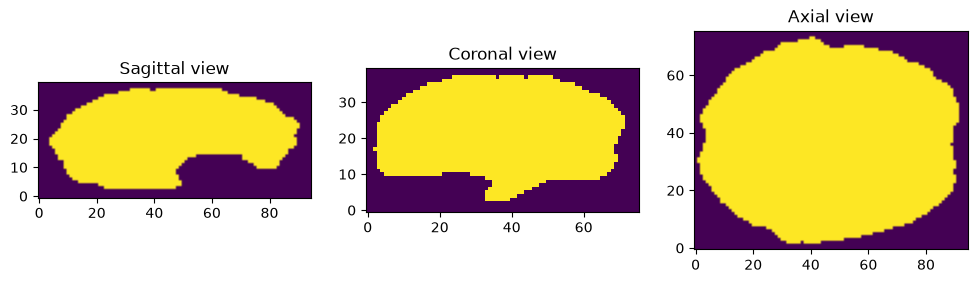

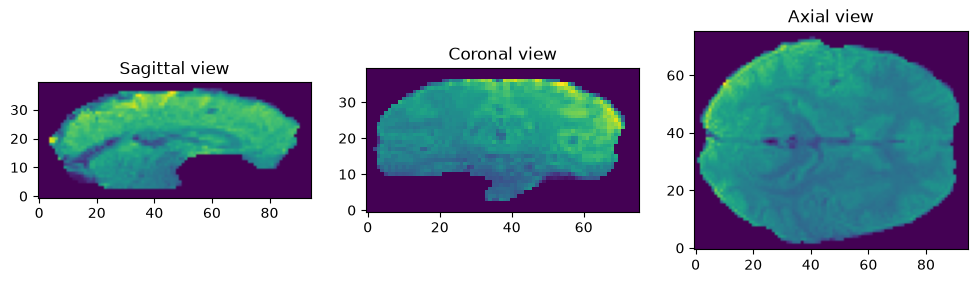

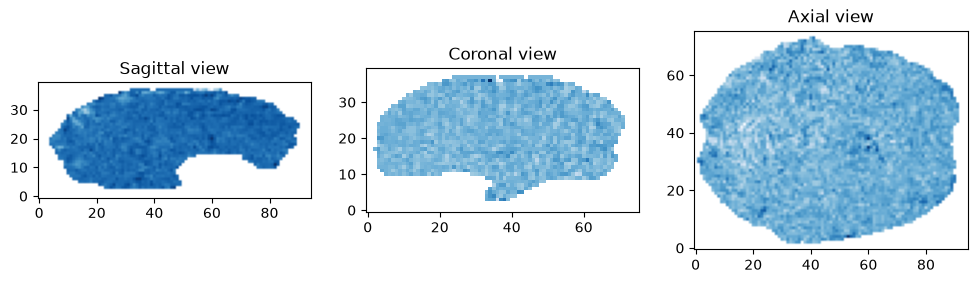

In [39]:
# Select an example subject within the group. 
example_subject = 'sub-xp104'

# Display sections of the brain mask through the sagittal, coronal, and axial views. 
display_brain_image(results_dict['group_brain_mask'], middle_coord)

# Display sections of the brain image through the sagittal, coronal, and axial views. 
display_brain_image(results_dict['group_brain_images'][example_subject], middle_coord)

# Display sections of the brain statistical map through the sagittal, coronal, and axial views. 
display_brain_image(results_dict['group_beta_maps'][example_subject], middle_coord, colormap = 'Blues')

In [40]:
# Run the analysis again, this time using the stored brain images and masks. 
stored_brain_images_and_masks = {
    'group_brain_images': results_dict['group_brain_images'],
    'group_brain_mask': results_dict['group_brain_mask']
}
results_dict = run_first_level_analysis_group(computational_model,
                                              train_valid_subjects, 
                                              nb_scans,
                                              brain_images_dict, 
                                              brain_masks_dict,
                                              neurofeedback_scores_dict, 
                                              movement_regressors_dict, 
                                              stored_brain_images_and_masks = stored_brain_images_and_masks)

# Store the results dictionary in a separate variable for later use. 
results_dict_cached = results_dict

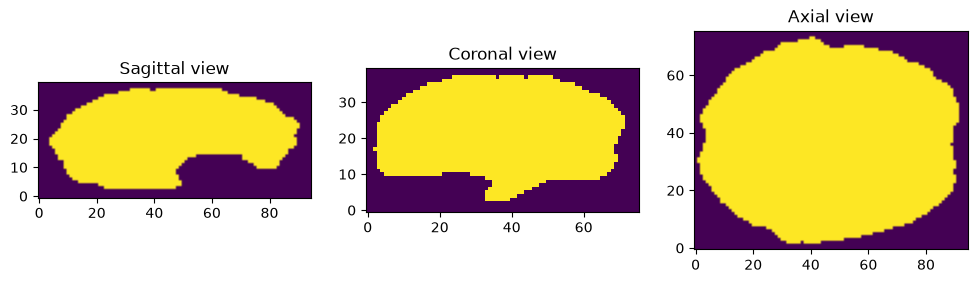

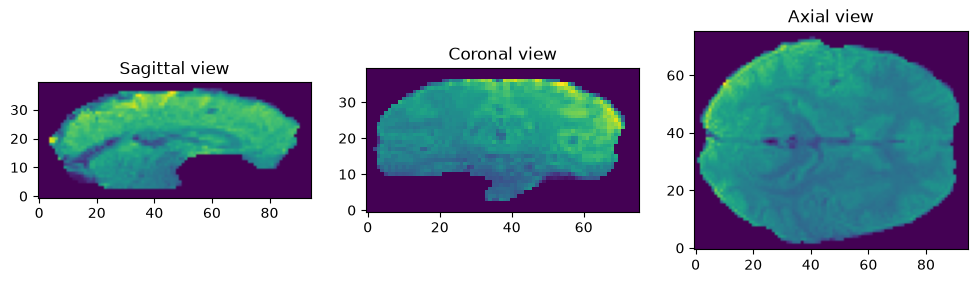

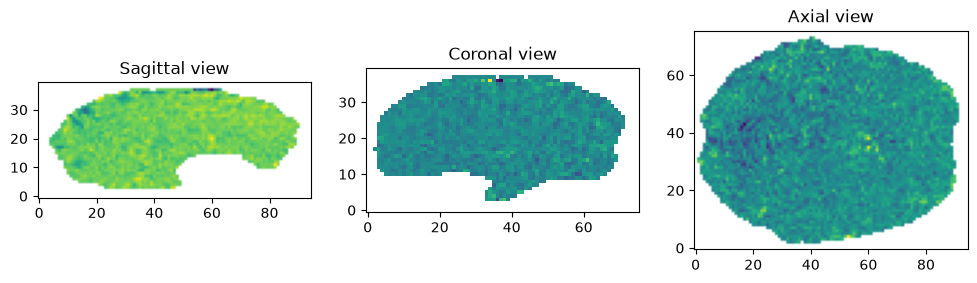

In [41]:
# Display sections of the brain mask through the sagittal, coronal, and axial views. 
display_brain_image(results_dict['group_brain_mask'], middle_coord)

# Display sections of the brain image through the sagittal, coronal, and axial views. 
display_brain_image(results_dict['group_brain_images'][example_subject], middle_coord)

# Display sections of the brain statistical map through the sagittal, coronal, and axial views. 
display_brain_image(results_dict['group_beta_maps'][example_subject], middle_coord)

In [42]:
# Verify that the results obtained with and without storing brain images and brain masks are identical. 
np.allclose(results_dict_uncached['group_beta_maps'][example_subject], 
            results_dict_cached['group_beta_maps'][example_subject], equal_nan = True)

True

### Neural generalization

Compute the neural generalization based on the similarity scores. 

In [43]:
# Define a function to evaluate neural generalization based on the similarity scores.
def evaluate_neural_generalization(
    results_dict, 
    group_subjects
):

    # Initialize a matrix to store the similarity scores. 
    similarity_scores_matrix = np.full((len(group_subjects), len(group_subjects)), np.nan)

    # Iterate through all subjects. 
    for subject_index, subject in enumerate(group_subjects):

        # Retrieve the beta map for the subject. 
        beta_map = results_dict['group_beta_maps'][subject]

        # Iterate through all other subjects to compute the similarity scores. 
        for other_subject_index, other_subject in enumerate(group_subjects):

            # Skip the subject if it has already been processed. 
            if other_subject_index <= subject_index:
                continue

            # Retrieve the beta map for the other subject. 
            other_beta_map = results_dict['group_beta_maps'][other_subject]

            # Compute the Pearson correlation coefficient between the two beta maps, considering only the voxels within the group brain mask. 
            similarity_score = np.corrcoef(
                beta_map.flatten()[results_dict['group_brain_mask'].flatten()],
                other_beta_map.flatten()[results_dict['group_brain_mask'].flatten()]
            )[0, 1]

            # Store the similarity score in the matrix. 
            similarity_scores_matrix[
                subject_index, other_subject_index
            ] = similarity_score

    # Flatten the similarity scores matrix and remove NaN values. 
    similarity_scores = similarity_scores_matrix.flatten()
    similarity_scores = similarity_scores[~np.isnan(similarity_scores)]

    # Compute the neural generalization score. 
    neural_generalization_score = np.mean(similarity_scores)

    return similarity_scores_matrix, similarity_scores, neural_generalization_score

In [44]:
# Evaluate and display the neural generalization score based on the similarity scores.
similarity_scores_matrix, similarity_scores, neural_generalization_score = evaluate_neural_generalization(results_dict, train_valid_subjects)
print(f'Neural generalization score: {neural_generalization_score}')

Neural generalization score: -0.0039245117092378086


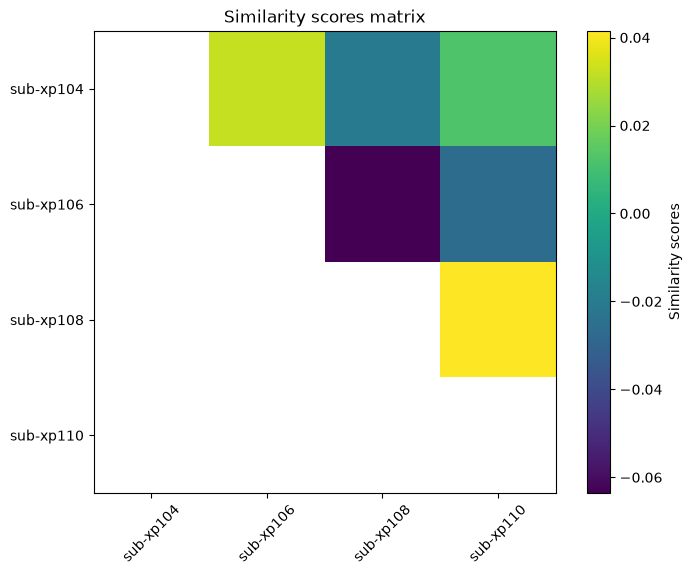

In [45]:
# Display the similarity scores matrix as a heatmap. 
plt.figure(figsize = (8, 6))
plt.imshow(similarity_scores_matrix, cmap = 'viridis', interpolation = 'nearest')
plt.colorbar(label = 'Similarity scores')
plt.xticks(range(len(train_valid_subjects)), train_valid_subjects, rotation = 45)
plt.yticks(range(len(train_valid_subjects)), train_valid_subjects)
plt.title('Similarity scores matrix')

# Save the similarity scores matrix heatmap. 
plt.savefig('similarity_scores_matrix.png', dpi = 300, bbox_inches = 'tight')

plt.show()

### Large language model (LLM)

Define the LLM to use (Gemma-4-E4B-IT), and generate examples of computational models. 

In [46]:
# Define the random seed. 
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)

In [47]:
# Define the LLM to use. 
model_id = "google/gemma-4-E4B-it"

# Use Apple's Metal backend if available. 
device = 'mps' if torch.backends.mps.is_available() else 'cpu'

# Load the processor and model. 
processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    dtype = torch.float16,
    low_cpu_mem_usage = True
).to(device)

# Set evaluation mode for inference. 
model.eval()

print(f'Model loaded on: {device}')

Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

Model loaded on: mps


In [48]:
# Define a function to generate text with Gemma. 
def generate_text(
    messages,
    max_new_tokens = 128,
    do_sample = True,
    temperature = 0.7 # stable: 0.7
):

    # Convert the chat messages into model inputs.
    inputs = processor.apply_chat_template(
        messages,
        tokenize = True,
        return_dict = True,
        return_tensors = 'pt',
        add_generation_prompt = True
    )
    inputs = {name: value.to(device) for name, value in inputs.items()}
    input_length = inputs['input_ids'].shape[-1]

    # Generate a response. 
    generation_arguments = {
        'max_new_tokens': max_new_tokens,
        'do_sample': do_sample
    }

    if do_sample:
        generation_arguments['temperature'] = temperature

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            **generation_arguments
        )

    # Keep only the tokens generated after the prompt. 
    generated_ids = output_ids[0][input_length:]

    return processor.decode(
        generated_ids,
        skip_special_tokens = True
    )

In [49]:
# Define a function to generate the prompt for creating a computational model. 
def generate_prompt_creation():
        
    # Create the prompt for the initial computational model creation. 
    prompt = [
        {
            'role': 'system',
            'content': (
                'You are a helpful scientific research assistant in cognitive and computational neuroscience. '
                'Your task is to generate Python-compatible polynomial formulas. '
                'Use only the variables x1, x2, and x3, and the Python operators +, -, *, and **. '
                'Numbers must be non-zero floats rounded to the 2nd decimal place. '
                'Polynomials are allowed up to the 2nd degree. '
                'Return only a formula on one line, without any explanation or additional elements.'
            )
        },
        {
            'role': 'user',
            'content': (
                'We are working with an fMRI dataset where neurofeedback scores are recorded over time. '
                'The variables x1, x2, and x3 represent these scores at different time windows. '
                'These scores are presented in reverse chronological order, with x1 being the most recent score. '
                'We are interested in modeling a latent variable to capture the influence of these scores. '
                'Generate a non-trivial polynomial model using x1, x2, and x3 to compute this latent variable. '
                'The polynomial should contain five terms, including at least one interaction term and at least one squared term. '
            )
        }
        ]

    return prompt

In [50]:
# Define a function to generate the prompt for modifying a computational model. 
def generate_prompt_modification(parent_model, nb_modifications = 1):
        
    # Define the number of modifications to apply. 
    if nb_modifications == 1:
        modification_text = 'Apply a single modification to this computational model to create a variant. '
        instructions_text = 'You can either add a new term, remove an existing term, or modify a coefficient of an existing term. '
    elif nb_modifications == 2:
        modification_text = 'Apply two modifications to this computational model to create a variant. '
        instructions_text = 'You can either add a new term, remove an existing term, or modify a coefficient of an existing term. '
    elif nb_modifications == 'remove_first_add_new':
        modification_text = 'Remove the first term of the polynomial, and create an entirely new term at the end. '
        instructions_text = 'This will create a variant of the computational model. '
    else:
        raise ValueError('The number of modifications must be set to 1, 2, or "remove_first_add_new".')
    
    # Create the prompt for the computational model modification. 
    prompt = [
        {
            'role': 'system',
            'content': (
                'You are a helpful scientific research assistant in cognitive and computational neuroscience. '
                'Your task is to generate Python-compatible polynomial formulas. '
                'Use only the variables x1, x2, and x3, and the Python operators +, -, *, and **. '
                'Numbers must be non-zero floats rounded to the 2nd decimal place. '
                'Polynomials are allowed up to the 2nd degree. '
                'Return only a formula on one line, without any explanation or additional elements.'
            )
        },
        {
            'role': 'user',
            'content': (
                'We are working with an fMRI dataset where neurofeedback scores are recorded over time. '
                'The variables x1, x2, and x3 represent these scores at different time windows. '
                'These scores are presented in reverse chronological order, with x1 being the most recent score. '
                'We are interested in modeling a latent variable to capture the influence of these scores. '
                f'Our previous computational model was the following:\n{parent_model}\n'
                f'{modification_text}'
                f'{instructions_text}'
                'The new computational model should still be a valid polynomial model.'
            )
        }
        ]

    return prompt

In [51]:
# Generate and display several different computational models. 
print('Computational model creation:')
for _ in range(5):
    prompt = generate_prompt_creation()
    response = generate_text(prompt)
    print(response)

Computational model creation:
1.23*x1**2ادرة + 0.45*x2**2ادرة + 0.11*x3 + 0.55*x1*x2 + 0.22*x1*x3
1.23*x1**2 + 0.55*x2**2 + 0.11*x3 + 0.22*x1*x2 + 0.50*x1*x3
1.1*x1**2 + 0.50*x2**2 + 0.25*x3**2 + 0.15*x1*x2 + -0.05*x1*x3
1.23*x1**2 + 0.54*x2**2 + 0.99*x1*x2 - 0.41*x1*x3 + 0.22*x3**2
1.50*x1**2 + 0.75*x2**2 + 0.22*x3**2 + 0.45*x1*x2 - 0.11*x1*x3


In [52]:
# Generate and display several different computational models. 
print('Computational model modification:')
for _ in range(5):
    prompt = generate_prompt_modification(parent_model = computational_model)
    response = generate_text(prompt)
    print(response)

Computational model modification:
x1 + 3.10*x2 + 5.25*x3 + x.**2 + 2.58*x1*x2
x1 + 3.70*x2 + 5.25*x3 + x2**2 + 2.58*x1*x2
x1 + 4.00*x2 + 5.25*x3 + x2**2 + 2.58*x1*x2
x1 + 3.10*x2 + 5.75*x3 + x2**2 + 2.58*x1*x2
x1 + 3.10*x2 + 5.75*x3 + x2**2 + 2.58*x1*x2


In [53]:
# Define a function to verify if a computational model is a valid polynomial. 
def is_valid_polynomial(computational_model):

    # Define the variables and operations allowed in a computational model. 
    allowed_variables = {'x1', 'x2', 'x3'}
    allowed_binary_operators = (ast.Add, ast.Sub, ast.Mult, ast.Pow)
    allowed_unary_operators = (ast.UAdd, ast.USub)

    # Define a recursive function to inspect an expression and compute its degree. 
    def compute_polynomial_degree(node):

        # A model variable has degree one. 
        if isinstance(node, ast.Name):

            if node.id not in allowed_variables:
                raise ValueError

            return 1

        # A finite numerical constant has degree zero. 
        if isinstance(node, ast.Constant):

            if (
                isinstance(node.value, bool)
                or not isinstance(node.value, (int, float))
                or not math.isfinite(node.value) or node.value == 0
            ):
                raise ValueError

            return 0

        # Positive and negative signs do not change the polynomial degree. 
        if isinstance(node, ast.UnaryOp):

            if not isinstance(node.op, allowed_unary_operators):
                raise ValueError

            return compute_polynomial_degree(node.operand)

        # Inspect binary operations. 
        if isinstance(node, ast.BinOp):

            if not isinstance(node.op, allowed_binary_operators):
                raise ValueError

            left_degree = compute_polynomial_degree(node.left)
            right_degree = compute_polynomial_degree(node.right)

            # For powers, require an integer exponent between zero and two. 
            if isinstance(node.op, ast.Pow):

                if (
                    not isinstance(node.right, ast.Constant)
                    or isinstance(node.right.value, bool)
                    or not isinstance(node.right.value, int)
                    or node.right.value not in {0, 1, 2}
                ):
                    raise ValueError

                return left_degree * node.right.value

            # Addition and subtraction retain the highest degree. 
            if isinstance(node.op, (ast.Add, ast.Sub)):
                return max(left_degree, right_degree)

            # Multiplication adds the degrees.
            if isinstance(node.op, ast.Mult):
                return left_degree + right_degree

        # Reject any other syntax, such as function calls or indexing. 
        raise ValueError

    try:

        # Parse the formula without executing it. 
        parsed_formula = ast.parse(computational_model.strip(), mode = 'eval')

        # Compute its degree and verify that it is a non-constant polynomial of degree at most two. 
        polynomial_degree = compute_polynomial_degree(parsed_formula.body)

        return 1 <= polynomial_degree <= 2

    except (SyntaxError, TypeError, ValueError):
        return False

In [54]:
# Evaluate the validity of several computational models. 
valid_polynomial = '1.17*x1 + 0.42*x2 - 0.12*x3 + 0.05*(x1**2)'
print(is_valid_polynomial(valid_polynomial), ':', valid_polynomial)
invalid_polynomial_1 = 'x1**3'
print(is_valid_polynomial(invalid_polynomial_1), ':', invalid_polynomial_1)
invalid_polynomial_2 = 'np.sin(x2)'
print(is_valid_polynomial(invalid_polynomial_2), ':', invalid_polynomial_2)
invalid_polynomial_3 = 'brain*cerveau*x3'
print(is_valid_polynomial(invalid_polynomial_3), ':', invalid_polynomial_3)
invalid_polynomial_4 = '0.00*x1 + 0.80*x2'
print(is_valid_polynomial(invalid_polynomial_4), ':', invalid_polynomial_4)

True : 1.17*x1 + 0.42*x2 - 0.12*x3 + 0.05*(x1**2)
False : x1**3
False : np.sin(x2)
False : brain*cerveau*x3
False : 0.00*x1 + 0.80*x2


In [55]:
# Define a function to create a valid computational model. 
def create_computational_model(max_attempts = 25):
    nb_failed_attempts = 0

    # Generate a computational model until a valid polynomial is obtained. 
    while True:
        prompt = generate_prompt_creation()
        response = generate_text(prompt)

        # Verify if the generated computational model is a valid polynomial. 
        if is_valid_polynomial(response):
            return response, nb_failed_attempts
        else:
            nb_failed_attempts += 1

            # If the number of failed attempts exceeds a threshold, raise an error. 
            if nb_failed_attempts >= max_attempts:
                raise RuntimeError(f'Failed to generate a valid computational model after {max_attempts} attempts.')

In [56]:
# Define a function to modify a computational model into another valid computational model. 
def modify_computational_model(parent_model, nb_modifications = 1, max_attempts = 25):
    nb_failed_attempts = 0

    # Generate a computational model until a valid polynomial is obtained. 
    while True:
        prompt = generate_prompt_modification(parent_model, nb_modifications = nb_modifications)
        response = generate_text(prompt)

        # Verify if the generated computational model is a valid polynomial, and if it is different from the parent model. 
        if is_valid_polynomial(response) and response != parent_model:
            return response, nb_failed_attempts
        else:
            nb_failed_attempts += 1

            # If the number of failed attempts exceeds a threshold, raise an error. 
            if nb_failed_attempts >= max_attempts:
                raise RuntimeError(f'Failed to generate a valid computational model after {max_attempts} attempts.')

In [57]:
# Create a valid computational model and display the number of failed attempts before success. 
response, nb_failed_attempts = create_computational_model()
print('Computational model creation: valid polynomial generated after', nb_failed_attempts, 'failed attempts')
print(response)

Computational model creation: valid polynomial generated after 0 failed attempts
1.23*x1**2 + 0.54*x2**2 - 0.99*x3 + 0.41*x1*x2 + 0.21*x1*x3


In [58]:
# Modify a computational model into another valid computational model, and display the number of failed attempts before success.
response, nb_failed_attempts = modify_computational_model(parent_model = computational_model)
print('Computational model modification: valid polynomial generated after', nb_failed_attempts, 'failed attempts')
print(response)

Computational model modification: valid polynomial generated after 5 failed attempts
x1 + 3.10*x2 + 5.75*x3 + x2**2 + 2.58*x1*x2


### Experiment

Run the experiment, then display and save the results. Computational models are created and modified using the LLM, and evaluated based on their neural generalization score. 

In [59]:
# Display the training and validation subjects, and the test subjects. 
print('Training and validation subjects:', train_valid_subjects)
print('Test subjects:                   ', test_subjects)

Training and validation subjects: ['sub-xp104', 'sub-xp106', 'sub-xp108', 'sub-xp110']
Test subjects:                    ['sub-xp105', 'sub-xp107', 'sub-xp109']


In [60]:
# Define computational model indexes for the entire series of models and for the incumbent models. 
computational_model_index = 0
incumbent_computational_model_index = 0

# Create the initial computational model. 
computational_model, nb_failed_attempts = create_computational_model()

# Create a dictionary to store the parent of each computational model.
parent_computational_model_indexes_dict = dict()
parent_computational_model_indexes_dict[computational_model_index] = None

# Evaluate the neural generalization score on the the training and validation subjects. 
results_dict_train_valid = run_first_level_analysis_group(computational_model, 
                                                          train_valid_subjects, 
                                                          nb_scans, 
                                                          brain_images_dict, 
                                                          brain_masks_dict, 
                                                          neurofeedback_scores_dict, 
                                                          movement_regressors_dict, 
                                                          stored_brain_images_and_masks = dict())
_, similarity_scores, neural_generalization_score = evaluate_neural_generalization(results_dict_train_valid, train_valid_subjects)

# Create dictionaries to store the computational models and their corresponding similarity scores and neural generalization scores. 
incumbent_computational_models_train_valid_dict = dict()
incumbent_computational_models_train_valid_dict[incumbent_computational_model_index] = (computational_model, 
                                                                                        similarity_scores, 
                                                                                        neural_generalization_score, 
                                                                                        computational_model_index)
computational_models_train_valid_dict = dict()
computational_models_train_valid_dict[computational_model_index] = (computational_model, 
                                                                    similarity_scores, 
                                                                    neural_generalization_score, 
                                                                    nb_failed_attempts)

# Define the best neural generalization score on the training and validation subjects. 
incumbent_neural_generalization_score = neural_generalization_score

# Display the initial computational model and neural generalization score. 
print('Creation - Computational model:', computational_model, ' | score:', neural_generalization_score, ' | failed attempts:', nb_failed_attempts)

# Evaluate the neural generalization score on the the test subjects. 
results_dict_test = run_first_level_analysis_group(computational_model, 
                                                   test_subjects, 
                                                   nb_scans, 
                                                   brain_images_dict, 
                                                   brain_masks_dict, 
                                                   neurofeedback_scores_dict, 
                                                   movement_regressors_dict, 
                                                   stored_brain_images_and_masks = dict())
_, similarity_scores, neural_generalization_score = evaluate_neural_generalization(results_dict_test, test_subjects)

# Create a dictionary to store the computational models and their corresponding similarity scores and neural generalization scores. 
incumbent_computational_models_test_dict = dict()
incumbent_computational_models_test_dict[incumbent_computational_model_index] = (computational_model, 
                                                                                 similarity_scores, 
                                                                                 neural_generalization_score)

# Define dictionaries to store the brain images and brain masks. 
stored_brain_images_and_masks_train_valid = {
    'group_brain_images': results_dict_train_valid['group_brain_images'],
    'group_brain_mask': results_dict_train_valid['group_brain_mask']
}
stored_brain_images_and_masks_test = {
    'group_brain_images': results_dict_test['group_brain_images'],
    'group_brain_mask': results_dict_test['group_brain_mask']
}

# Inner loop: iteratively modify and evaluate the computational model. 
for iteration in range(10):

    # Select the best computational model based on the neural generalization score, and retrieve its index. 
    incumbent_computational_model = incumbent_computational_models_train_valid_dict[incumbent_computational_model_index][0]
    parent_computational_model_index = incumbent_computational_models_train_valid_dict[incumbent_computational_model_index][3]

    # Update the incumbent computational model index. 
    incumbent_computational_model_index = incumbent_computational_model_index + 1

    # Generate and evaluate three variants by modifying the incumbent computational model. 
    for variant in range(3):

        # Define the number of failed attempts for this variant. 
        nb_failed_attempts_variant = 0
        new_variant_found = False

        # Iterate five times to create a new variant of the incumbent computational model with a single modification. 
        for attempt in range(5):

            # Modify the incumbent computational model to create a new variant. 
            computational_model, nb_failed_attempts = modify_computational_model(parent_model = incumbent_computational_model)
            nb_failed_attempts_variant += nb_failed_attempts

            # If the variant is valid and not already evaluated, break the loop. 
            if computational_model not in [model_index[0] for model_index in computational_models_train_valid_dict.values()]:
                new_variant_found = True
                break
            else:
                nb_failed_attempts_variant += 1

        # If no new variant was found after five attempts, apply two modifications instead of one. 
        if not new_variant_found:
            computational_model, nb_failed_attempts = modify_computational_model(parent_model = incumbent_computational_model, nb_modifications = 2)
            nb_failed_attempts_variant += nb_failed_attempts

            # If applying two modifications does not result in a new variant, remove the first term of the polynomial and add a new term. 
            if computational_model in [model_index[0] for model_index in computational_models_train_valid_dict.values()]:
                computational_model, nb_failed_attempts = modify_computational_model(parent_model = incumbent_computational_model, nb_modifications = 'remove_first_add_new')
                nb_failed_attempts_variant += nb_failed_attempts
        
        # Increment the computational model index and store its parent index. 
        computational_model_index += 1
        parent_computational_model_indexes_dict[computational_model_index] = parent_computational_model_index

        # Evaluate the neural generalization score on the training and validation subjects. 
        results_dict_train_valid = run_first_level_analysis_group(computational_model, 
                                                                  train_valid_subjects, 
                                                                  nb_scans, 
                                                                  brain_images_dict, 
                                                                  brain_masks_dict, 
                                                                  neurofeedback_scores_dict, 
                                                                  movement_regressors_dict, 
                                                                  stored_brain_images_and_masks = stored_brain_images_and_masks_train_valid)
        _, similarity_scores, neural_generalization_score = evaluate_neural_generalization(results_dict_train_valid, train_valid_subjects)

        # Store the computational model and its corresponding similarity scores and neural generalization score. 
        computational_models_train_valid_dict[computational_model_index] = (computational_model, 
                                                                            similarity_scores, 
                                                                            neural_generalization_score, 
                                                                            nb_failed_attempts_variant)

        # Display the current computational model variant and neural generalization score. 
        print('Iteration', iteration, '- Computational model variant:', computational_model, ' | score:', neural_generalization_score, ' | failed attempts:', nb_failed_attempts_variant)

    # Select the best computational model so far based on the neural generalization score. 
    best_computational_model_index = max(computational_models_train_valid_dict, key = lambda x: computational_models_train_valid_dict[x][2])
    best_computational_model = computational_models_train_valid_dict[best_computational_model_index][0]
    best_neural_generalization_score = computational_models_train_valid_dict[best_computational_model_index][2]

    # If the best computational model is better than the incumbent, update the incumbent and evaluate on the test set. 
    if best_neural_generalization_score > incumbent_neural_generalization_score:

        # Display a message indicating that a better computational model has been found. 
        print('Iteration', iteration, '- Better computational model found:', best_computational_model, ' | score:', best_neural_generalization_score)

        # Update the incumbent computational model neural generalization score. 
        incumbent_neural_generalization_score = best_neural_generalization_score

        # Update the incumbent computational models dictionary. 
        incumbent_computational_models_train_valid_dict[incumbent_computational_model_index] = (best_computational_model, 
                                                                                               computational_models_train_valid_dict[best_computational_model_index][1], 
                                                                                               incumbent_neural_generalization_score, 
                                                                                               best_computational_model_index)

        # Evaluate the neural generalization score on the the test subjects. 
        results_dict_test = run_first_level_analysis_group(best_computational_model, 
                                                           test_subjects, 
                                                           nb_scans,
                                                           brain_images_dict, 
                                                           brain_masks_dict,
                                                           neurofeedback_scores_dict, 
                                                           movement_regressors_dict, 
                                                           stored_brain_images_and_masks = stored_brain_images_and_masks_test)
        _, similarity_scores, neural_generalization_score = evaluate_neural_generalization(results_dict_test, test_subjects)

        # Update the incumbent computational models dictionary for the test subjects. 
        incumbent_computational_models_test_dict[incumbent_computational_model_index] = (best_computational_model, 
                                                                                        similarity_scores, 
                                                                                        neural_generalization_score)

    # Otherwise, duplicate the previous incumbent computational model and its corresponding similarity scores and neural generalization score. 
    else:
        incumbent_computational_models_train_valid_dict[incumbent_computational_model_index] = incumbent_computational_models_train_valid_dict[incumbent_computational_model_index - 1]
        incumbent_computational_models_test_dict[incumbent_computational_model_index] = incumbent_computational_models_test_dict[incumbent_computational_model_index - 1]



Creation - Computational model: 1.25*x1**2 + 0.55*x2**2 + 0.22*x3**2 + 0.15*x1*x2 - 0.05*x1*x3  | score: -0.004636839578280917  | failed attempts: 0
Iteration 0 - Computational model variant: 1.25*x1**2 + 0.55*x2**2 + 0.22*x3**2 + 0.15*x1*x2 - 0.05*x1*x3 + 0.01*x1*x3  | score: -0.0045820765554769605  | failed attempts: 1
Iteration 0 - Computational model variant: 1.25*x1**2 + 0.55*x2**2 + 0.22*x3**2 + 0.15*x1*x2 - 0.05*x1*x3 + 0.01*x1*x2  | score: -0.004629937646909523  | failed attempts: 3
Iteration 0 - Computational model variant: 1.25*x1**2 + 0.55*x2**2 + 0.22*x3**2 + 0.15*x1*x2 + 0.02*x1*x3  | score: -0.004257389293542941  | failed attempts: 1
Iteration 0 - Better computational model found: 1.25*x1**2 + 0.55*x2**2 + 0.22*x3**2 + 0.15*x1*x2 + 0.02*x1*x3  | score: -0.004257389293542941
Iteration 1 - Computational model variant: 1.25*x1**2 + 0.55*x2**2 + 0.22*x3**2 + 0.15*x1*x2 + 0.02*x1*x3 + 0.05*x1*x3  | score: -0.003992148349688113  | failed attempts: 0
Iteration 1 - Computational 

In [61]:
# Define a function to visualize the evolution of neural generalization scores. 
def plot_neural_generalization_evolution(computational_models_dict, set_type, error_bars, color, save_image = False, image_filename = None):

    # Define labels for the two possible data sets. 
    set_type_labels = {
        'train_valid': 'Training and Validation',
        'test': 'Test'
    }
    if set_type not in set_type_labels:
        raise ValueError("set_type must be either 'train_valid' or 'test'.")

    # Retrieve entries in chronological search order. 
    model_indexes = sorted(computational_models_dict.keys())
    neural_generalization_scores = np.array(
        [
            computational_models_dict[model_index][2]
            for model_index in model_indexes
        ],
        dtype = float
    )

    # Compute the standard error across unique pairwise correlations. 
    standard_errors = []
    for model_index in model_indexes:

        # Retrieve the similarity scores for the current model index. 
        similarity_scores = np.asarray(
            computational_models_dict[model_index][1],
            dtype = float
        )
        similarity_scores = similarity_scores[np.isfinite(similarity_scores)]

        # Compute the standard error of the mean for the similarity scores. 
        if len(similarity_scores) > 1:
            standard_error = (
                np.std(similarity_scores, ddof = 1)
                / np.sqrt(len(similarity_scores))
            )
        else:
            standard_error = np.nan
        standard_errors.append(standard_error)
    standard_errors = np.array(standard_errors)

    # Create the plot. 
    fig, ax = plt.subplots(figsize = (7, 5))
    ax.plot(model_indexes, neural_generalization_scores, color = color, marker = 'o', markersize = 5, linewidth = 2)
    if error_bars:
        ax.errorbar(model_indexes, neural_generalization_scores, yerr = standard_errors, 
                    fmt = 'none', ecolor = color, elinewidth = 1, capsize = 3, alpha = 0.5)
    
    # Add labels and title. 
    ax.set_title('Evolution of the neural generalization score — ' + set_type_labels[set_type])
    ax.set_xlabel('Search iteration')
    ax.set_ylabel('Neural generalization score')
    ax.set_xticks(model_indexes)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()

    # If save_image is True, save the figure to the specified image_filename. 
    if save_image:
        plt.savefig(image_filename, dpi = 300, bbox_inches = 'tight')

    plt.show()

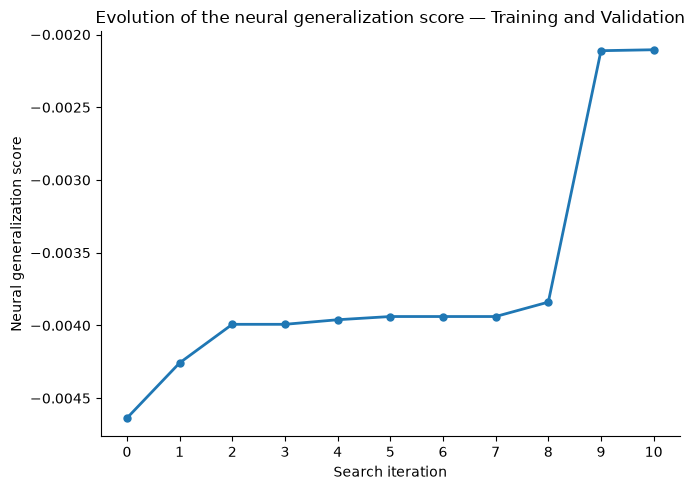

In [62]:
# Plot the evolution of neural generalization scores for the training and validation subjects. 
plot_neural_generalization_evolution(incumbent_computational_models_train_valid_dict, set_type = 'train_valid', 
                                     error_bars = False, color = 'tab:blue', 
                                     save_image = True, image_filename = 'neural_generalization_train_valid_plot.png')

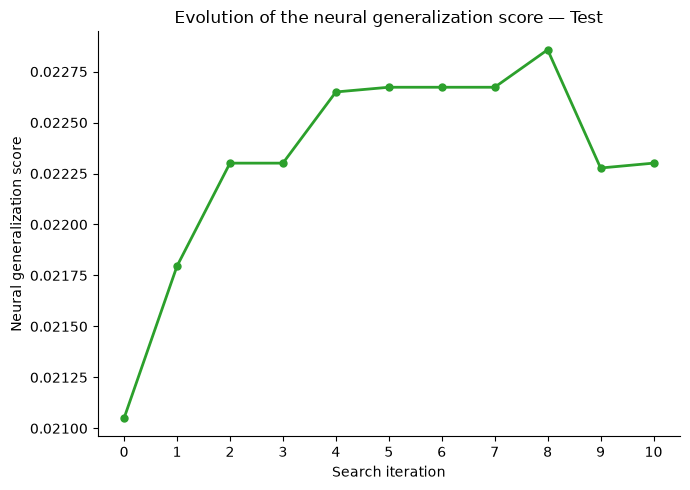

In [63]:
# Plot the evolution of neural generalization scores for the test subjects. 
plot_neural_generalization_evolution(incumbent_computational_models_test_dict, set_type = 'test', 
                                     error_bars = False, color = 'tab:green', 
                                     save_image = True, image_filename = 'neural_generalization_test_plot.png')

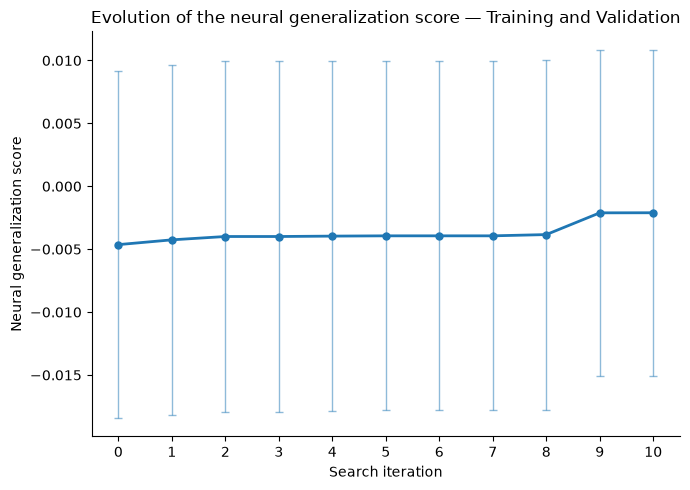

In [64]:
# Plot the evolution of neural generalization scores for the training and validation subjects, with error bars. 
plot_neural_generalization_evolution(incumbent_computational_models_train_valid_dict, set_type = 'train_valid', 
                                     error_bars = True, color = 'tab:blue', 
                                     save_image = True, image_filename = 'neural_generalization_train_valid_plot_with_error_bars.png')

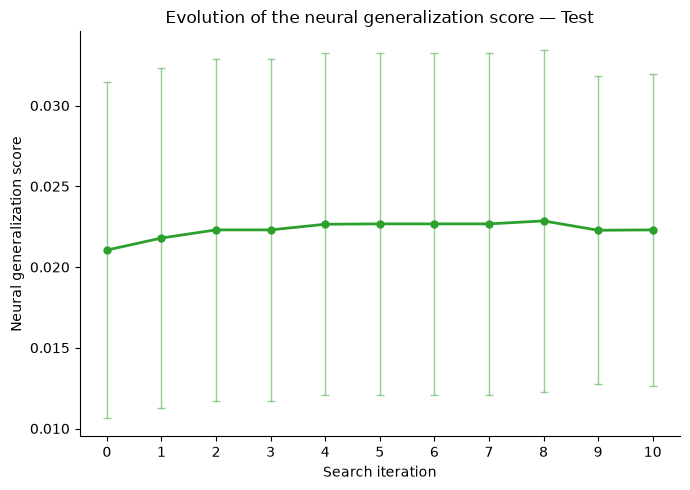

In [65]:
# Plot the evolution of neural generalization scores for the test subjects, with error bars. 
plot_neural_generalization_evolution(incumbent_computational_models_test_dict, set_type = 'test', 
                                     error_bars = True, color = 'tab:green', 
                                     save_image = True, image_filename = 'neural_generalization_test_plot_with_error_bars.png')

In [66]:
# Save the results of the inner loop in a Pickle file. 
inner_loop_results = {
    'computational_models_train_valid_dict': computational_models_train_valid_dict,
    'parent_computational_model_indexes_dict': parent_computational_model_indexes_dict,
    'incumbent_computational_models_train_valid_dict': incumbent_computational_models_train_valid_dict,
    'incumbent_computational_models_test_dict': incumbent_computational_models_test_dict
}
with open('inner_loop_results.pkl', 'wb') as results_file:
    pickle.dump(inner_loop_results, results_file)

In [67]:
# Define a list to store the information of all computational models. 
all_models_rows = []

# Iterate through the computational models and their corresponding results. 
for model_index, model_results in computational_models_train_valid_dict.items():

    # Retrieve the computational model, similarity scores, neural generalization score, and number of failed attempts. 
    computational_model = model_results[0]
    similarity_scores = model_results[1]
    neural_generalization_score = model_results[2]
    nb_failed_attempts = model_results[3]

    all_models_rows.append(
        {
            'computational_model_index': model_index, 
            'parent_computational_model_index': parent_computational_model_indexes_dict[model_index], 
            'computational_model': computational_model, 
            'train_valid_similarity_scores': json.dumps(np.asarray(similarity_scores, dtype = float).tolist()), 
            'train_valid_neural_generalization_score': neural_generalization_score, 
            'nb_failed_attempts': nb_failed_attempts
        }
    )

# Save the evaluated computational models of the inner loop in a CSV file. 
all_models_dataframe = pd.DataFrame(all_models_rows)
all_models_dataframe.to_csv('all_computational_models.csv', index = False)

In [68]:
# Define a list to store the information of the incumbent computational models. 
incumbent_rows = []

# Iterate through the incumbent computational models and their corresponding results. 
for search_iteration in incumbent_computational_models_train_valid_dict:

    # Retrieve the training and validation results and the test results for the current search iteration. 
    train_valid_results = incumbent_computational_models_train_valid_dict[search_iteration]
    test_results = incumbent_computational_models_test_dict[search_iteration]

    incumbent_rows.append(
        {
            'search_iteration': search_iteration, 
            'computational_model_index': train_valid_results[3], 
            'computational_model': train_valid_results[0], 
            'train_valid_similarity_scores': json.dumps(np.asarray(train_valid_results[1], dtype = float).tolist()), 
            'train_valid_neural_generalization_score': train_valid_results[2], 
            'test_similarity_scores': json.dumps(np.asarray(test_results[1], dtype = float).tolist()), 
            'test_neural_generalization_score': test_results[2]
        }
    )

# Save the incumbent computational models of the inner loop in a CSV file. 
incumbent_dataframe = pd.DataFrame(incumbent_rows)
incumbent_dataframe.to_csv('incumbent_trajectory.csv', index = False)

In [69]:
# Save all evaluated computational models in plain text, with one formula per line.
with open('all_computational_models.txt', 'w') as text_file:
    for model_results in computational_models_train_valid_dict.values():
        text_file.write(model_results[0] + '\n')

# Save incumbent computational models in plain text, with one formula per line.
with open('incumbent_computational_models.txt', 'w') as text_file:
    for model_results in incumbent_computational_models_train_valid_dict.values():
        text_file.write(model_results[0] + '\n')